In [7]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import os

print("Python environment is ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Project setup completed successfully!")

Python environment is ready!
Pandas version: 3.1.1
NumPy version: 2.5.4
Project setup completed successfully!


In [8]:
import pandas as pd
import numpy as np
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
import os

# Set project directory
project_path = r"C:\Acciojob\task\Ipo_analysis_DA14"

# Check files in raw folder
raw_path = os.path.join(project_path, "data", "raw")

print(os.listdir(raw_path))

['ipo_master_raw.csv']


In [10]:
# Read IPO master dataset
ipo_df = pd.read_csv(
    os.path.join(raw_path, "ipo_master_raw.csv")
)

# Display first 5 records
ipo_df.head()

,COMPANY NAME,SECURITY TYPE,ISSUE PRICE,Symbol,ISSUE START DATE,ISSUE END DATE,PRICE RANGE,DATE OF LISTING
0,Studds Accessories Limited,EQ,585,STUDDS,30-OCT-2025,03-NOV-2025,Rs.557 to Rs.585,07-NOV-2025
1,Orkla India Limited,EQ,730,ORKLAINDIA,29-OCT-2025,31-OCT-2025,Rs.695 to Rs.730,06-NOV-2025
2,Jayesh Logistics Limited,SME,122,JAYESH,27-OCT-2025,29-OCT-2025,RS.116 to RS.122,03-NOV-2025
3,SMC Global Securities Limited,DEBT,-,SMCG03,16-OCT-2025,24-OCT-2025,Rs.1000,-
4,SMC Global Securities Limited,DEBT,-,SMCG03,16-OCT-2025,24-OCT-2025,Rs.1000,-


In [11]:
ipo_df.shape

(765, 8)

In [12]:
ipo_df.columns.tolist()

['COMPANY NAME',
 'SECURITY TYPE',
 'ISSUE PRICE',
 'Symbol',
 'ISSUE START DATE',
 'ISSUE END DATE',
 'PRICE RANGE',
 'DATE OF LISTING']

In [13]:
ipo_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   COMPANY NAME      765 non-null    str  
 1   SECURITY TYPE     765 non-null    str  
 2   ISSUE PRICE       765 non-null    str  
 3   Symbol            765 non-null    str  
 4   ISSUE START DATE  765 non-null    str  
 5   ISSUE END DATE    765 non-null    str  
 6   PRICE RANGE       765 non-null    str  
 7   DATE OF LISTING   765 non-null    str  
dtypes: str(8)
memory usage: 47.9 KB


In [14]:
ipo_df.isnull().sum()

COMPANY NAME        0
SECURITY TYPE       0
ISSUE PRICE         0
Symbol              0
ISSUE START DATE    0
ISSUE END DATE      0
PRICE RANGE         0
DATE OF LISTING     0
dtype: int64

In [15]:
ipo_df.duplicated().sum()

np.int64(54)

In [16]:
ipo_df.head(20)

,COMPANY NAME,SECURITY TYPE,ISSUE PRICE,Symbol,ISSUE START DATE,ISSUE END DATE,PRICE RANGE,DATE OF LISTING
0,Studds Accessories Limited,EQ,585,STUDDS,30-OCT-2025,03-NOV-2025,Rs.557 to Rs.585,07-NOV-2025
1,Orkla India Limited,EQ,730,ORKLAINDIA,29-OCT-2025,31-OCT-2025,Rs.695 to Rs.730,06-NOV-2025
2,Jayesh Logistics Limited,SME,122,JAYESH,27-OCT-2025,29-OCT-2025,RS.116 to RS.122,03-NOV-2025
3,SMC Global Securities Limited,DEBT,-,SMCG03,16-OCT-2025,24-OCT-2025,Rs.1000,-
4,SMC Global Securities Limited,DEBT,-,SMCG03,16-OCT-2025,24-OCT-2025,Rs.1000,-
5,Midwest Limited,EQ,1065,MIDWESTLTD,15-OCT-2025,17-OCT-2025,Rs.1014 to Rs.1065,24-OCT-2025
6,Canara HSBC Life Insurance Company Limited,N0,######,815CHLI36,10-OCT-2025,14-OCT-2025,Rs.100 to Rs.106,17-MAR-2026
7,Canara HSBC Life Insurance Company Limited,N0,######,815CHLI36,10-OCT-2025,14-OCT-2025,Rs.100 to Rs.106,17-MAR-2026
8,Canara Robeco Asset Management Company Limited,EQ,266,CRAMC,09-OCT-2025,13-OCT-2025,Rs.253 to Rs.266,16-OCT-2025
9,Rubicon Research Limited,EQ,485,RUBICON,09-OCT-2025,13-OCT-2025,Rs.461 to Rs.485,16-OCT-2025


### Step 2 – Filter and clean the IPO master dataset

In [17]:
# Step 1: Create a working copy
ipo_clean = ipo_df.copy()

# Step 2: Remove unnecessary spaces from text columns
ipo_clean.columns = ipo_clean.columns.str.strip()

ipo_clean["SECURITY TYPE"] = ipo_clean["SECURITY TYPE"].astype(str).str.strip()
ipo_clean["COMPANY NAME"] = ipo_clean["COMPANY NAME"].astype(str).str.strip()
ipo_clean["Symbol"] = ipo_clean["Symbol"].astype(str).str.strip()

# Step 3: Convert issue price into a numeric column
ipo_clean["ISSUE PRICE"] = pd.to_numeric(
    ipo_clean["ISSUE PRICE"].astype(str).str.strip().str.replace(",", ""),
    errors="coerce"
)

# Step 4: Convert listing date into proper date format
ipo_clean["DATE OF LISTING"] = pd.to_datetime(
    ipo_clean["DATE OF LISTING"].replace("-", pd.NA),
    format="%d-%b-%Y",
    errors="coerce"
)

# Step 5: Keep only equity IPOs
ipo_clean = ipo_clean[
    ipo_clean["SECURITY TYPE"] == "EQ"
].copy()

# Step 6: Filter using the selected listing-date range
start_date = "2022-10-30"
end_date = "2025-10-30"

ipo_clean = ipo_clean[
    ipo_clean["DATE OF LISTING"].between(start_date, end_date)
].copy()

# Step 7: Check for duplicate rows
print("Duplicate rows:", ipo_clean.duplicated().sum())

# Step 8: Create a flag for missing issue prices
ipo_clean["PRICE_STATUS"] = np.where(
    ipo_clean["ISSUE PRICE"].isna(),
    "Needs verification",
    "Valid"
)

# Step 9: Sort by listing date
ipo_clean = ipo_clean.sort_values(
    by="DATE OF LISTING"
).reset_index(drop=True)

# Step 10: View the cleaned dataset
print("Cleaned dataset shape:", ipo_clean.shape)

display(ipo_clean.head(10))

Duplicate rows: 0
Cleaned dataset shape: (195, 9)


,COMPANY NAME,SECURITY TYPE,ISSUE PRICE,Symbol,ISSUE START DATE,ISSUE END DATE,PRICE RANGE,DATE OF LISTING,PRICE_STATUS
0,Fusion Micro Finance Limited,EQ,368.0,FUSION,02-NOV-2022,04-NOV-2022,Rs.350 to Rs.368,2022-11-15,Valid
1,Global Health Limited,EQ,336.0,MEDANTA,03-NOV-2022,07-NOV-2022,Rs.319 to Rs.336,2022-11-16,Valid
2,Bikaji Foods International Limited,EQ,300.0,BIKAJI,03-NOV-2022,07-NOV-2022,Rs.285 to Rs.300,2022-11-16,Valid
3,Archean Chemical Industries Limited,EQ,407.0,ACI,09-NOV-2022,11-NOV-2022,Rs.386 to Rs.407,2022-11-21,Valid
4,FiveStar Business Finance Limited,EQ,474.0,FIVESTAR,09-NOV-2022,11-NOV-2022,Rs.450 to Rs.474,2022-11-21,Valid
5,Kaynes Technology India Limited,EQ,587.0,KAYNES,10-NOV-2022,14-NOV-2022,Rs.559 to Rs.587,2022-11-22,Valid
6,Inox Green Energy Services Limited,EQ,65.0,INOXGREEN,11-NOV-2022,15-NOV-2022,Rs.61 to Rs.65,2022-11-23,Valid
7,Keystone Realtors Limited,EQ,541.0,RUSTOMJEE,14-NOV-2022,16-NOV-2022,Rs.514 to Rs.541,2022-11-24,Valid
8,Dharmaj Crop Guard Limited,EQ,237.0,DHARMAJ,28-NOV-2022,30-NOV-2022,Rs.216 to Rs.237\t,2022-12-08,Valid
9,Uniparts India Limited,EQ,577.0,UNIPARTS,30-NOV-2022,02-DEC-2022,Rs.548 to Rs.577,2022-12-12,Valid


In [18]:
ipo_df.to_csv(
    os.path.join(project_path, "data", "processed", "ipo_master_backup.csv"),
    index=False
)

print("IPO master backup saved successfully!")

IPO master backup saved successfully!


In [19]:
print("Total IPOs:", len(ipo_clean))

print("\nMissing values:")
print(ipo_clean.isnull().sum())

print("\nListing date range:")
print(ipo_clean["DATE OF LISTING"].min())
print(ipo_clean["DATE OF LISTING"].max())

print("\nIssue price verification:")
display(
    ipo_clean[ipo_clean["ISSUE PRICE"].isna()][
        ["COMPANY NAME", "Symbol", "DATE OF LISTING", "ISSUE PRICE"]
    ]
)

Total IPOs: 195

Missing values:
COMPANY NAME        0
SECURITY TYPE       0
ISSUE PRICE         1
Symbol              0
ISSUE START DATE    0
ISSUE END DATE      0
PRICE RANGE         0
DATE OF LISTING     0
PRICE_STATUS        0
dtype: int64

Listing date range:
2022-11-15 00:00:00
2025-10-24 00:00:00

Issue price verification:


,COMPANY NAME,Symbol,DATE OF LISTING,ISSUE PRICE
80,Vodafone Idea Limited - FPO,IDEAFPO,2024-04-25,NaN


### Step 3 – Prepare IPO analysis cohort

In [20]:
# Keep a separate copy for the main IPO analysis
ipo_analysis = ipo_clean.copy()

# Exclude FPO records from the IPO analysis
ipo_analysis = ipo_analysis[
    ~ipo_analysis["COMPANY NAME"].str.contains(
        "FPO", case=False, na=False
    )
].copy()

# Exclude records without a valid issue price
ipo_analysis = ipo_analysis[
    ipo_analysis["ISSUE PRICE"].notna()
].copy()

# Create Yahoo Finance ticker symbols
ipo_analysis["YF_TICKER"] = (
    ipo_analysis["Symbol"].astype(str).str.strip() + ".NS"
)

# Reset index
ipo_analysis = ipo_analysis.reset_index(drop=True)

print("IPO records for main analysis:", len(ipo_analysis))
display(
    ipo_analysis[
        ["COMPANY NAME", "Symbol", "YF_TICKER",
         "ISSUE PRICE", "DATE OF LISTING"]
    ].head(10)
)

IPO records for main analysis: 194


,COMPANY NAME,Symbol,YF_TICKER,ISSUE PRICE,DATE OF LISTING
0,Fusion Micro Finance Limited,FUSION,FUSION.NS,368.0,2022-11-15
1,Global Health Limited,MEDANTA,MEDANTA.NS,336.0,2022-11-16
2,Bikaji Foods International Limited,BIKAJI,BIKAJI.NS,300.0,2022-11-16
3,Archean Chemical Industries Limited,ACI,ACI.NS,407.0,2022-11-21
4,FiveStar Business Finance Limited,FIVESTAR,FIVESTAR.NS,474.0,2022-11-21
5,Kaynes Technology India Limited,KAYNES,KAYNES.NS,587.0,2022-11-22
6,Inox Green Energy Services Limited,INOXGREEN,INOXGREEN.NS,65.0,2022-11-23
7,Keystone Realtors Limited,RUSTOMJEE,RUSTOMJEE.NS,541.0,2022-11-24
8,Dharmaj Crop Guard Limited,DHARMAJ,DHARMAJ.NS,237.0,2022-12-08
9,Uniparts India Limited,UNIPARTS,UNIPARTS.NS,577.0,2022-12-12


In [21]:
import os

project_path = r"C:\Acciojob\task\Ipo_analysis_DA14"

processed_path = os.path.join(
    project_path,
    "data",
    "processed"
)

# Create the folder if it doesn't exist
os.makedirs(processed_path, exist_ok=True)

print("Processed folder:", processed_path)

Processed folder: C:\Acciojob\task\Ipo_analysis_DA14\data\processed


In [22]:
ipo_analysis.to_csv(
    os.path.join(processed_path, "ipo_analysis_cohort.csv"),
    index=False
)

print("IPO analysis cohort saved successfully!")

IPO analysis cohort saved successfully!


In [23]:
print("IPO records:", len(ipo_analysis))

IPO records: 194


### Step 4 – Test historical stock price download

In [24]:
import yfinance as yf

test_ticker = "FUSION.NS"

test_data = yf.download(
    test_ticker,
    start="2022-11-15",
    end="2022-12-01",
    auto_adjust=False,
    progress=False
)

print("Rows downloaded:", len(test_data))
display(test_data.head())

Rows downloaded: 12


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,FUSION.NS,FUSION.NS,FUSION.NS,FUSION.NS,FUSION.NS,FUSION.NS
Date,,,,,,
2022-11-15,324.799988,324.799988,364.799988,321.100006,359.500000,16728869
2022-11-16,345.450012,345.450012,348.649994,323.500000,325.000000,3678285
2022-11-17,340.450012,340.450012,346.399994,334.299988,343.000000,598178
2022-11-18,336.649994,336.649994,344.500000,335.000000,341.950012,382364
2022-11-21,342.950012,342.950012,347.000000,327.700012,336.000000,1246319


In [25]:
# Flatten the two-level column headers
test_data.columns = test_data.columns.get_level_values(0)

# Display simplified data
display(test_data.head())

# Check column names
print(test_data.columns.tolist())

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2022-11-15,324.799988,324.799988,364.799988,321.100006,359.500000,16728869
2022-11-16,345.450012,345.450012,348.649994,323.500000,325.000000,3678285
2022-11-17,340.450012,340.450012,346.399994,334.299988,343.000000,598178
2022-11-18,336.649994,336.649994,344.500000,335.000000,341.950012,382364
2022-11-21,342.950012,342.950012,347.000000,327.700012,336.000000,1246319


['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [26]:
# Get the first trading day's closing price
listing_day_close = test_data.iloc[0]["Close"]

# Get the IPO issue price
issue_price = 368

# Calculate listing-day return
listing_return = (
    (listing_day_close - issue_price) / issue_price
) * 100

print("Issue Price:", issue_price)
print("Listing Day Close:", listing_day_close)
print("Listing Day Return:", round(listing_return, 2), "%")

Issue Price: 368
Listing Day Close: 324.79998779296875
Listing Day Return: -11.74 %


### Step 5 – Bulk historical stock price collection

In [27]:
import yfinance as yf
import pandas as pd
import time
import os

# Store all downloaded stock prices
all_stock_prices = []

# Track successful and unsuccessful downloads
download_log = []

for index, row in ipo_analysis.iterrows():

    company = row["COMPANY NAME"]
    ticker = row["YF_TICKER"]
    listing_date = row["DATE OF LISTING"]

    start_date = listing_date.strftime("%Y-%m-%d")

    # End date is exclusive in yfinance
    end_date = "2026-10-31"

    try:
        stock_data = yf.download(
            ticker,
            start=start_date,
            end=end_date,
            auto_adjust=False,
            progress=False
        )

        if not stock_data.empty:

            # Flatten multi-level columns, if present
            if isinstance(stock_data.columns, pd.MultiIndex):
                stock_data.columns = (
                    stock_data.columns.get_level_values(0)
                )

            stock_data = stock_data.reset_index()

            stock_data["COMPANY NAME"] = company
            stock_data["YF_TICKER"] = ticker

            all_stock_prices.append(stock_data)

            download_log.append({
                "COMPANY NAME": company,
                "YF_TICKER": ticker,
                "STATUS": "Success",
                "ROWS": len(stock_data)
            })

        else:
            download_log.append({
                "COMPANY NAME": company,
                "YF_TICKER": ticker,
                "STATUS": "No data",
                "ROWS": 0
            })

    except Exception as e:

        download_log.append({
            "COMPANY NAME": company,
            "YF_TICKER": ticker,
            "STATUS": "Failed: " + str(e)[:100],
            "ROWS": 0
        })

    # Short pause between requests
    time.sleep(0.5)

    print(f"Processed {index + 1}/{len(ipo_analysis)}: {ticker}")


# Combine all downloaded stock prices
if all_stock_prices:
    historical_prices = pd.concat(
        all_stock_prices,
        ignore_index=True
    )

else:
    historical_prices = pd.DataFrame()


# Create download status report
download_status = pd.DataFrame(download_log)

print("\nDownload Summary")
print(download_status["STATUS"].value_counts())

print("\nHistorical price dataset shape:")
print(historical_prices.shape)

Processed 1/194: FUSION.NS
Processed 2/194: MEDANTA.NS
Processed 3/194: BIKAJI.NS
Processed 4/194: ACI.NS
Processed 5/194: FIVESTAR.NS
Processed 6/194: KAYNES.NS
Processed 7/194: INOXGREEN.NS
Processed 8/194: RUSTOMJEE.NS
Processed 9/194: DHARMAJ.NS
Processed 10/194: UNIPARTS.NS
Processed 11/194: SULA.NS


$AHL.NS: possibly delisted; no timezone found

1 Failed download:
['AHL.NS']: possibly delisted; no timezone found


Processed 12/194: AHL.NS
Processed 13/194: LANDMARK.NS
Processed 14/194: KFINTECH.NS
Processed 15/194: ELIN.NS
Processed 16/194: RADIANTCMS.NS
Processed 17/194: DIVGIITTS.NS
Processed 18/194: AVALON.NS
Processed 19/194: MANKIND.NS
Processed 20/194: IKIO.NS
Processed 21/194: HMAAGRO.NS
Processed 22/194: IDEAFORGE.NS
Processed 23/194: CYIENTDLM.NS
Processed 24/194: SENCO.NS
Processed 25/194: UTKARSHBNK.NS
Processed 26/194: NETWEB.NS
Processed 27/194: YATHARTH.NS
Processed 28/194: SBFC.NS
Processed 29/194: CONCORDBIO.NS
Processed 30/194: TVSSCS.NS
Processed 31/194: AEROFLEX.NS
Processed 32/194: VPRPL.NS
Processed 33/194: RISHABH.NS
Processed 34/194: JLHL.NS
Processed 35/194: RRKABEL.NS
Processed 36/194: EMSLIMITED.NS
Processed 37/194: SAMHI.NS
Processed 38/194: ZAGGLE.NS
Processed 39/194: SIGNATURE.NS
Processed 40/194: KALAMANDIR.NS
Processed 41/194: YATRA.NS
Processed 42/194: MVGJL.NS
Processed 43/194: JSWINFRA.NS
Processed 44/194: UDS.NS
Processed 45/194: IRMENERGY.NS
Processed 46/194: 

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: SGLTL.NS"}}}
$SGLTL.NS: possibly delisted; no timezone found

1 Failed download:
['SGLTL.NS']: possibly delisted; no timezone found


Processed 135/194: SGLTL.NS
Processed 136/194: QUADFUTURE.NS
Processed 137/194: LAXMIDENTL.NS
Processed 138/194: AGARWALEYE.NS
Processed 139/194: PROTEAN.NS
Processed 140/194: AJAXENGG.NS
Processed 141/194: HEXT.NS
Processed 142/194: QPOWER.NS
Processed 143/194: ATHERENERG.NS
Processed 144/194: BELRISE.NS
Processed 145/194: THELEELA.NS
Processed 146/194: OSWALPUMPS.NS


$ARISINFRA.NS: possibly delisted; no timezone found

1 Failed download:
['ARISINFRA.NS']: possibly delisted; no timezone found


Processed 147/194: ARISINFRA.NS
Processed 148/194: ELLEN.NS
Processed 149/194: KALPATARU.NS
Processed 150/194: HDBFS.NS
Processed 151/194: SAMBHV.NS
Processed 152/194: CRIZAC.NS
Processed 153/194: TRAVELFOOD.NS
Processed 154/194: SMARTWORKS.NS
Processed 155/194: ANTHEM.NS
Processed 156/194: INDIQUBE.NS
Processed 157/194: EBGNG.NS
Processed 158/194: BRIGHOTEL.NS
Processed 159/194: SHANTIGOLD.NS
Processed 160/194: LAXMIINDIA.NS
Processed 161/194: CPPLUS.NS
Processed 162/194: LOTUSDEV.NS
Processed 163/194: MBEL.NS
Processed 164/194: ALLTIME.NS
Processed 165/194: JSWCEMENT.NS
Processed 166/194: BLUESTONE.NS
Processed 167/194: REGAAL.NS
Processed 168/194: SHREEJISPG.NS
Processed 169/194: VIKRAMSOLR.NS
Processed 170/194: GEMAROMA.NS
Processed 171/194: MEIL.NS
Processed 172/194: VIKRAN.NS
Processed 173/194: URBANCO.NS
Processed 174/194: SHRINGARMS.NS
Processed 175/194: EUROPRATIK.NS
Processed 176/194: IVALUE.NS
Processed 177/194: GKENERGY.NS


$SAATVIK.NS: possibly delisted; no timezone found

1 Failed download:
['SAATVIK.NS']: possibly delisted; no timezone found


Processed 178/194: SAATVIK.NS
Processed 179/194: ATLANTAELE.NS
Processed 180/194: GANESHCP.NS
Processed 181/194: JARO.NS
Processed 182/194: SOLARWORLD.NS
Processed 183/194: ARSSBL.NS
Processed 184/194: STYL.NS
Processed 185/194: EPACKPEB.NS
Processed 186/194: JAINREC.NS
Processed 187/194: TRUALT.NS
Processed 188/194: PACEDIGITK.NS
Processed 189/194: GLOTTIS.NS
Processed 190/194: WEWORK.NS
Processed 191/194: LGEINDIA.NS
Processed 192/194: RUBICON.NS
Processed 193/194: CRAMC.NS
Processed 194/194: MIDWESTLTD.NS

Download Summary
STATUS
Success    190
No data      4
Name: count, dtype: int64

Historical price dataset shape:
(107282, 9)


In [28]:
historical_prices.to_csv(
    os.path.join(processed_path, "historical_stock_prices.csv"),
    index=False
)

download_status.to_csv(
    os.path.join(processed_path, "stock_download_status.csv"),
    index=False
)

print("Historical prices and download report saved!")

Historical prices and download report saved!


In [29]:
# Show companies for which Yahoo Finance returned no data
no_data_tickers = download_status[
    download_status["STATUS"] == "No data"
]

display(no_data_tickers)

,COMPANY NAME,YF_TICKER,STATUS,ROWS
11,Abans Holdings Limited,AHL.NS,No data,0
134,Standard Glass Lining Technology Limited,SGLTL.NS,No data,0
146,Arisinfra Solutions Limited,ARISINFRA.NS,No data,0
177,Saatvik Green Energy Limited,SAATVIK.NS,No data,0


In [30]:
# Get the full IPO details for those four companies
missing_companies = ipo_analysis[
    ipo_analysis["YF_TICKER"].isin(
        no_data_tickers["YF_TICKER"]
    )
]

display(
    missing_companies[
        [
            "COMPANY NAME",
            "Symbol",
            "YF_TICKER",
            "ISSUE PRICE",
            "DATE OF LISTING"
        ]
    ]
)

,COMPANY NAME,Symbol,YF_TICKER,ISSUE PRICE,DATE OF LISTING
11,Abans Holdings Limited,AHL,AHL.NS,270.0,2022-12-23
134,Standard Glass Lining Technology Limited,SGLTL,SGLTL.NS,140.0,2025-01-13
146,Arisinfra Solutions Limited,ARISINFRA,ARISINFRA.NS,222.0,2025-06-25
177,Saatvik Green Energy Limited,SAATVIK,SAATVIK.NS,465.0,2025-09-26


In [31]:
print("Total rows:", len(historical_prices))

print("\nMissing values:")
print(historical_prices.isnull().sum())

print("\nDate range:")
print(historical_prices["Date"].min())
print(historical_prices["Date"].max())

print("\nDuplicate company-date records:")
print(
    historical_prices.duplicated(
        subset=["YF_TICKER", "Date"]
    ).sum()
)

Total rows: 107282

Missing values:
Price
Date            0
Adj Close       0
Close           0
High            0
Low             0
Open            0
Volume          0
COMPANY NAME    0
YF_TICKER       0
dtype: int64

Date range:
2022-11-15 00:00:00
2026-10-30 00:00:00

Duplicate company-date records:
0


In [32]:
# Convert Date column to datetime
historical_prices["Date"] = pd.to_datetime(
    historical_prices["Date"]
)

# Basic dataset checks
print("Total rows:", len(historical_prices))

print("\nDate range:")
print("Start:", historical_prices["Date"].min())
print("End:", historical_prices["Date"].max())

print("\nMissing Close prices:")
print(historical_prices["Close"].isna().sum())

print("\nDuplicate ticker-date records:")
print(
    historical_prices.duplicated(
        subset=["YF_TICKER", "Date"]
    ).sum()
)

print("\nUnique tickers downloaded:")
print(historical_prices["YF_TICKER"].nunique())

Total rows: 107282

Date range:
Start: 2022-11-15 00:00:00
End: 2026-10-30 00:00:00

Missing Close prices:
0

Duplicate ticker-date records:
0

Unique tickers downloaded:
190


In [33]:
# Find the first available trading date for each ticker
first_price_dates = (
    historical_prices
    .sort_values("Date")
    .groupby("YF_TICKER")
    .first()
    .reset_index()[["YF_TICKER", "Date"]]
    .rename(columns={"Date": "FIRST_PRICE_DATE"})
)

# Join with the IPO master data
date_check = ipo_analysis[
    ["COMPANY NAME", "YF_TICKER", "DATE OF LISTING"]
].merge(
    first_price_dates,
    on="YF_TICKER",
    how="left"
)

date_check["DATE OF LISTING"] = pd.to_datetime(
    date_check["DATE OF LISTING"]
)

date_check["DATE_MATCH"] = (
    date_check["DATE OF LISTING"] ==
    date_check["FIRST_PRICE_DATE"]
)

display(date_check.head(15))

print("\nFirst-price date mismatches:")
print((~date_check["DATE_MATCH"]).sum())

,COMPANY NAME,YF_TICKER,DATE OF LISTING,FIRST_PRICE_DATE,DATE_MATCH
0,Fusion Micro Finance Limited,FUSION.NS,2022-11-15,2022-11-15,True
1,Global Health Limited,MEDANTA.NS,2022-11-16,2022-11-18,False
2,Bikaji Foods International Limited,BIKAJI.NS,2022-11-16,2022-11-16,True
3,Archean Chemical Industries Limited,ACI.NS,2022-11-21,2022-11-21,True
4,FiveStar Business Finance Limited,FIVESTAR.NS,2022-11-21,2022-11-21,True
5,Kaynes Technology India Limited,KAYNES.NS,2022-11-22,2022-11-22,True
6,Inox Green Energy Services Limited,INOXGREEN.NS,2022-11-23,2022-11-23,True
7,Keystone Realtors Limited,RUSTOMJEE.NS,2022-11-24,2022-11-24,True
8,Dharmaj Crop Guard Limited,DHARMAJ.NS,2022-12-08,2022-12-08,True
9,Uniparts India Limited,UNIPARTS.NS,2022-12-12,2022-12-12,True



First-price date mismatches:
9


In [34]:
# Display all listing-date mismatches
mismatches = date_check[
    date_check["DATE_MATCH"] == False
].copy()

display(
    mismatches[
        [
            "COMPANY NAME",
            "YF_TICKER",
            "DATE OF LISTING",
            "FIRST_PRICE_DATE"
        ]
    ]
)

print("Total mismatches:", len(mismatches))

,COMPANY NAME,YF_TICKER,DATE OF LISTING,FIRST_PRICE_DATE
1,Global Health Limited,MEDANTA.NS,2022-11-16,2022-11-18
11,Abans Holdings Limited,AHL.NS,2022-12-23,NaT
124,International Gemmological Institute (India) L...,IGIL.NS,2024-12-20,2024-12-30
134,Standard Glass Lining Technology Limited,SGLTL.NS,2025-01-13,NaT
146,Arisinfra Solutions Limited,ARISINFRA.NS,2025-06-25,NaT
177,Saatvik Green Energy Limited,SAATVIK.NS,2025-09-26,NaT
184,Epack Prefab Technologies Limited,EPACKPEB.NS,2025-10-01,2025-10-06
185,Jain Resource Recycling Limited,JAINREC.NS,2025-10-01,2025-10-06
186,TruAlt Bioenergy Limited,TRUALT.NS,2025-10-03,2025-10-06


Total mismatches: 9


In [35]:
# Inspect historical records around each mismatched listing date

for _, row in mismatches.iterrows():

    ticker = row["YF_TICKER"]
    listing_date = row["DATE OF LISTING"]

    print("\nCompany:", row["COMPANY NAME"])
    print("Ticker:", ticker)
    print("Listing date:", listing_date)

    check_data = historical_prices[
        historical_prices["YF_TICKER"] == ticker
    ].copy()

    check_data["Date"] = pd.to_datetime(check_data["Date"])

    # Show records from 5 calendar days before
    # through 10 calendar days after listing
    nearby_data = check_data[
        (check_data["Date"] >= listing_date - pd.Timedelta(days=5)) &
        (check_data["Date"] <= listing_date + pd.Timedelta(days=10))
    ]

    display(nearby_data[["Date", "Open", "High", "Low", "Close"]])


Company: Global Health Limited
Ticker: MEDANTA.NS
Listing date: 2022-11-16 00:00:00


Price,Date,Open,High,Low,Close
978,2022-11-18,417.350006,422.799988,406.649994,414.149994
979,2022-11-21,413.799988,431.950012,407.250000,429.750000
980,2022-11-22,428.000000,438.899994,424.000000,435.500000
981,2022-11-23,437.899994,457.450012,435.500000,450.899994
982,2022-11-24,453.899994,487.750000,442.000000,460.149994
983,2022-11-25,462.450012,469.000000,450.250000,451.799988



Company: Abans Holdings Limited
Ticker: AHL.NS
Listing date: 2022-12-23 00:00:00


Price,Date,Open,High,Low,Close



Company: International Gemmological Institute (India) Limited
Ticker: IGIL.NS
Listing date: 2024-12-20 00:00:00


Price,Date,Open,High,Low,Close
85034,2024-12-30,582.0,583.900024,547.25,554.549988


... (8 outputs left out)


Company: Jain Resource Recycling Limited
Ticker: JAINREC.NS
Listing date: 2025-10-01 00:00:00


Price,Date,Open,High,Low,Close
104939,2025-10-06,306.000000,341.700012,298.200012,311.149994
104940,2025-10-07,314.000000,342.769989,310.320007,324.040009
104941,2025-10-08,329.899994,339.799988,320.100006,325.260010
104942,2025-10-09,327.700012,356.600006,320.299988,342.450012
104943,2025-10-10,347.000000,351.000000,336.470001,347.010010



Company: TruAlt Bioenergy Limited
Ticker: TRUALT.NS
Listing date: 2025-10-03 00:00:00


Price,Date,Open,High,Low,Close
105204,2025-10-06,533.000000,534.500000,505.600006,510.899994
105205,2025-10-07,513.000000,518.000000,500.000000,504.750000
105206,2025-10-08,504.700012,510.850006,490.000000,494.149994
105207,2025-10-09,494.000000,515.599976,494.000000,503.100006
105208,2025-10-10,505.000000,524.900024,505.000000,519.700012
105209,2025-10-13,519.700012,524.900024,510.000000,512.349976


In [36]:
# Create a separate exception report
listing_exceptions = mismatches.copy()

listing_exceptions["ISSUE_TYPE"] = listing_exceptions[
    "FIRST_PRICE_DATE"
].isna().map({
    True: "No Yahoo Finance data",
    False: "Listing-day price missing"
})

listing_exceptions["DAYS_DELAYED"] = (
    listing_exceptions["FIRST_PRICE_DATE"]
    - listing_exceptions["DATE OF LISTING"]
).dt.days

display(
    listing_exceptions[
        [
            "COMPANY NAME",
            "YF_TICKER",
            "DATE OF LISTING",
            "FIRST_PRICE_DATE",
            "ISSUE_TYPE",
            "DAYS_DELAYED"
        ]
    ]
)

,COMPANY NAME,YF_TICKER,DATE OF LISTING,FIRST_PRICE_DATE,ISSUE_TYPE,DAYS_DELAYED
1,Global Health Limited,MEDANTA.NS,2022-11-16,2022-11-18,Listing-day price missing,2.0
11,Abans Holdings Limited,AHL.NS,2022-12-23,NaT,No Yahoo Finance data,NaN
124,International Gemmological Institute (India) L...,IGIL.NS,2024-12-20,2024-12-30,Listing-day price missing,10.0
134,Standard Glass Lining Technology Limited,SGLTL.NS,2025-01-13,NaT,No Yahoo Finance data,NaN
146,Arisinfra Solutions Limited,ARISINFRA.NS,2025-06-25,NaT,No Yahoo Finance data,NaN
177,Saatvik Green Energy Limited,SAATVIK.NS,2025-09-26,NaT,No Yahoo Finance data,NaN
184,Epack Prefab Technologies Limited,EPACKPEB.NS,2025-10-01,2025-10-06,Listing-day price missing,5.0
185,Jain Resource Recycling Limited,JAINREC.NS,2025-10-01,2025-10-06,Listing-day price missing,5.0
186,TruAlt Bioenergy Limited,TRUALT.NS,2025-10-03,2025-10-06,Listing-day price missing,3.0


In [37]:
listing_exceptions.to_csv(
    os.path.join(
        processed_path,
        "listing_date_exceptions.csv"
    ),
    index=False
)

print("Listing exception report saved!")

Listing exception report saved!


### Step 6 – Calculate Listing Day, 6-Month and 12-Month Returns

In [38]:
# Ensure date columns are in datetime format
historical_prices["Date"] = pd.to_datetime(
    historical_prices["Date"]
)

ipo_analysis["DATE OF LISTING"] = pd.to_datetime(
    ipo_analysis["DATE OF LISTING"]
)

# Sort historical prices
historical_prices = historical_prices.sort_values(
    ["YF_TICKER", "Date"]
).reset_index(drop=True)

print("Historical price data prepared.")

Historical price data prepared.


In [39]:
# Store the calculated results
ipo_returns = []

for _, ipo in ipo_analysis.iterrows():

    company = ipo["COMPANY NAME"]
    ticker = ipo["YF_TICKER"]
    issue_price = ipo["ISSUE PRICE"]
    listing_date = ipo["DATE OF LISTING"]

    # Get historical prices for this company
    stock = historical_prices[
        historical_prices["YF_TICKER"] == ticker
    ].copy()

    stock = stock.sort_values("Date")

    # Define milestone dates
    six_month_date = listing_date + pd.DateOffset(months=6)
    twelve_month_date = listing_date + pd.DateOffset(months=12)

    # 1. Exact listing-day closing price
    listing_price = stock.loc[
        stock["Date"] == listing_date, "Close"
    ]

    listing_close = (
        listing_price.iloc[0] if not listing_price.empty else np.nan
    )

    # 2. First available close on or after 6-month anniversary
    six_month_prices = stock[
        stock["Date"] >= six_month_date
    ]

    six_month_close = (
        six_month_prices.iloc[0]["Close"]
        if not six_month_prices.empty else np.nan
    )

    six_month_actual_date = (
        six_month_prices.iloc[0]["Date"]
        if not six_month_prices.empty else pd.NaT
    )

    # 3. First available close on or after 12-month anniversary
    twelve_month_prices = stock[
        stock["Date"] >= twelve_month_date
    ]

    twelve_month_close = (
        twelve_month_prices.iloc[0]["Close"]
        if not twelve_month_prices.empty else np.nan
    )

    twelve_month_actual_date = (
        twelve_month_prices.iloc[0]["Date"]
        if not twelve_month_prices.empty else pd.NaT
    )

    # Calculate returns relative to IPO issue price
    listing_return = (
        (listing_close - issue_price) / issue_price * 100
        if pd.notna(listing_close) else np.nan
    )

    six_month_return = (
        (six_month_close - issue_price) / issue_price * 100
        if pd.notna(six_month_close) else np.nan
    )

    twelve_month_return = (
        (twelve_month_close - issue_price) / issue_price * 100
        if pd.notna(twelve_month_close) else np.nan
    )

    # Store results
    ipo_returns.append({
        "COMPANY NAME": company,
        "YF_TICKER": ticker,
        "ISSUE PRICE": issue_price,
        "LISTING DATE": listing_date,

        "LISTING CLOSE": listing_close,
        "LISTING RETURN (%)": listing_return,

        "6M TARGET DATE": six_month_date,
        "6M ACTUAL DATE": six_month_actual_date,
        "6M CLOSE": six_month_close,
        "6M RETURN (%)": six_month_return,

        "12M TARGET DATE": twelve_month_date,
        "12M ACTUAL DATE": twelve_month_actual_date,
        "12M CLOSE": twelve_month_close,
        "12M RETURN (%)": twelve_month_return
    })


# Convert results into DataFrame
ipo_returns_df = pd.DataFrame(ipo_returns)

display(ipo_returns_df.head(10))

,COMPANY NAME,YF_TICKER,ISSUE PRICE,LISTING DATE,LISTING CLOSE,LISTING RETURN (%),6M TARGET DATE,6M ACTUAL DATE,6M CLOSE,6M RETURN (%),12M TARGET DATE,12M ACTUAL DATE,12M CLOSE,12M RETURN (%)
0,Fusion Micro Finance Limited,FUSION.NS,368.0,2022-11-15,324.799988,-11.739134,2023-05-15,2023-05-15,450.700012,22.472829,2023-11-15,2023-11-15,597.150024,62.269028
1,Global Health Limited,MEDANTA.NS,336.0,2022-11-16,NaN,NaN,2023-05-16,2023-05-16,572.500000,70.386905,2023-11-16,2023-11-16,888.500000,164.434524
2,Bikaji Foods International Limited,BIKAJI.NS,300.0,2022-11-16,317.450012,5.816671,2023-05-16,2023-05-16,369.850006,23.283335,2023-11-16,2023-11-16,549.099976,83.033325
3,Archean Chemical Industries Limited,ACI.NS,407.0,2022-11-21,458.149994,12.567566,2023-05-21,2023-05-22,542.849976,33.378372,2023-11-21,2023-11-21,525.049988,29.004911
4,FiveStar Business Finance Limited,FIVESTAR.NS,474.0,2022-11-21,490.000000,3.375527,2023-05-21,2023-05-22,529.349976,11.677210,2023-11-21,2023-11-21,803.599976,69.535860
5,Kaynes Technology India Limited,KAYNES.NS,587.0,2022-11-22,689.950012,17.538333,2023-05-22,2023-05-22,1306.949951,122.649055,2023-11-22,2023-11-22,2491.149902,324.386695
6,Inox Green Energy Services Limited,INOXGREEN.NS,65.0,2022-11-23,59.099998,-9.076925,2023-05-23,2023-05-23,46.849998,-27.923079,2023-11-23,2023-11-23,68.949997,6.076918
7,Keystone Realtors Limited,RUSTOMJEE.NS,541.0,2022-11-24,556.849976,2.929755,2023-05-24,2023-05-24,509.100006,-5.896487,2023-11-24,2023-11-24,536.650024,-0.804062
8,Dharmaj Crop Guard Limited,DHARMAJ.NS,237.0,2022-12-08,266.299988,12.362864,2023-06-08,2023-06-08,174.500000,-26.371308,2023-12-08,2023-12-08,262.899994,10.928267
9,Uniparts India Limited,UNIPARTS.NS,577.0,2022-12-12,539.650024,-6.473133,2023-06-12,2023-06-12,567.750000,-1.603120,2023-12-12,2023-12-12,549.950012,-4.688039


In [40]:
print("Total IPOs:", len(ipo_returns_df))

print("\nMissing return values:")
print(
    ipo_returns_df[
        [
            "LISTING RETURN (%)",
            "6M RETURN (%)",
            "12M RETURN (%)"
        ]
    ].isna().sum()
)

Total IPOs: 194

Missing return values:
LISTING RETURN (%)    9
6M RETURN (%)         4
12M RETURN (%)        4
dtype: int64


In [41]:
missing_listing_returns = ipo_returns_df[
    ipo_returns_df["LISTING RETURN (%)"].isna()
]

display(
    missing_listing_returns[
        [
            "COMPANY NAME",
            "YF_TICKER",
            "LISTING DATE",
            "LISTING CLOSE",
            "6M CLOSE",
            "12M CLOSE"
        ]
    ]
)

,COMPANY NAME,YF_TICKER,LISTING DATE,LISTING CLOSE,6M CLOSE,12M CLOSE
1,Global Health Limited,MEDANTA.NS,2022-11-16,NaN,572.500000,888.500000
11,Abans Holdings Limited,AHL.NS,2022-12-23,NaN,NaN,NaN
124,International Gemmological Institute (India) L...,IGIL.NS,2024-12-20,NaN,345.950012,321.149994
134,Standard Glass Lining Technology Limited,SGLTL.NS,2025-01-13,NaN,NaN,NaN
146,Arisinfra Solutions Limited,ARISINFRA.NS,2025-06-25,NaN,NaN,NaN
177,Saatvik Green Energy Limited,SAATVIK.NS,2025-09-26,NaN,NaN,NaN
184,Epack Prefab Technologies Limited,EPACKPEB.NS,2025-10-01,NaN,138.770004,242.070007
185,Jain Resource Recycling Limited,JAINREC.NS,2025-10-01,NaN,464.700012,282.500000
186,TruAlt Bioenergy Limited,TRUALT.NS,2025-10-03,NaN,421.450012,442.299988


In [42]:
ipo_returns_df.to_csv(
    os.path.join(
        processed_path,
        "ipo_returns_analysis.csv"
    ),
    index=False
)

print("IPO returns dataset saved successfully!")

IPO returns dataset saved successfully!


In [43]:
# Calculate the number of calendar days between target and actual dates

ipo_returns_df["6M_DELAY_DAYS"] = (
    ipo_returns_df["6M_ACTUAL_DATE"] -
    ipo_returns_df["6M_TARGET_DATE"]
).dt.days

ipo_returns_df["12M_DELAY_DAYS"] = (
    ipo_returns_df["12M_ACTUAL_DATE"] -
    ipo_returns_df["12M_TARGET_DATE"]
).dt.days

# Check unusually large delays
ipo_returns_df[
    (ipo_returns_df["6M_DELAY_DAYS"] > 7) |
    (ipo_returns_df["12M_DELAY_DAYS"] > 7)
][[
    "COMPANY NAME",
    "6M_TARGET_DATE",
    "6M_ACTUAL_DATE",
    "6M_DELAY_DAYS",
    "12M_TARGET_DATE",
    "12M_ACTUAL_DATE",
    "12M_DELAY_DAYS"
]]

KeyError: '6M_ACTUAL_DATE'

In [44]:
print(ipo_returns_df.columns.tolist())

['COMPANY NAME', 'YF_TICKER', 'ISSUE PRICE', 'LISTING DATE', 'LISTING CLOSE', 'LISTING RETURN (%)', '6M TARGET DATE', '6M ACTUAL DATE', '6M CLOSE', '6M RETURN (%)', '12M TARGET DATE', '12M ACTUAL DATE', '12M CLOSE', '12M RETURN (%)']


In [45]:
# Convert date columns into datetime format
date_columns = [
    "6M TARGET DATE",
    "6M ACTUAL DATE",
    "12M TARGET DATE",
    "12M ACTUAL DATE"
]

for col in date_columns:
    ipo_returns_df[col] = pd.to_datetime(ipo_returns_df[col])

# Calculate delay in calendar days
ipo_returns_df["6M DELAY DAYS"] = (
    ipo_returns_df["6M ACTUAL DATE"] -
    ipo_returns_df["6M TARGET DATE"]
).dt.days

ipo_returns_df["12M DELAY DAYS"] = (
    ipo_returns_df["12M ACTUAL DATE"] -
    ipo_returns_df["12M TARGET DATE"]
).dt.days

In [46]:
delay_check = ipo_returns_df[
    (ipo_returns_df["6M DELAY DAYS"] > 7) |
    (ipo_returns_df["12M DELAY DAYS"] > 7)
]

delay_check[[
    "COMPANY NAME",
    "6M TARGET DATE",
    "6M ACTUAL DATE",
    "6M DELAY DAYS",
    "12M TARGET DATE",
    "12M ACTUAL DATE",
    "12M DELAY DAYS"
]]

,COMPANY NAME,6M TARGET DATE,6M ACTUAL DATE,6M DELAY DAYS,12M TARGET DATE,12M ACTUAL DATE,12M DELAY DAYS


In [47]:
print("6-Month delay distribution:")
print(ipo_returns_df["6M DELAY DAYS"].value_counts(dropna=False).sort_index())

print("\n12-Month delay distribution:")
print(ipo_returns_df["12M DELAY DAYS"].value_counts(dropna=False).sort_index())

6-Month delay distribution:
6M DELAY DAYS
0.0    149
1.0     20
2.0     18
3.0      3
NaN      4
Name: count, dtype: int64

12-Month delay distribution:
12M DELAY DAYS
0.0    146
1.0     11
2.0     29
3.0      4
NaN      4
Name: count, dtype: int64


In [48]:
print("Maximum 6M delay:",
      ipo_returns_df["6M DELAY DAYS"].max())

print("Maximum 12M delay:",
      ipo_returns_df["12M DELAY DAYS"].max())

Maximum 6M delay: 3.0
Maximum 12M delay: 3.0


In [49]:
ipo_returns_df.to_csv(
    os.path.join(processed_path, "ipo_returns_analysis.csv"),
    index=False
)

print("Updated IPO returns dataset saved successfully!")

Updated IPO returns dataset saved successfully!


In [50]:
# Final dataset validation

print("Total IPOs:", len(ipo_returns_df))

print("\nUnique companies:",
      ipo_returns_df["COMPANY NAME"].nunique())

print("\nDuplicate companies:",
      ipo_returns_df["COMPANY NAME"].duplicated().sum())

print("\nMissing return values:")
print(
    ipo_returns_df[
        ["LISTING RETURN (%)", "6M RETURN (%)", "12M RETURN (%)"]
    ].isna().sum()
)

print("\nDate delay validation:")
print("Maximum 6M delay:",
      ipo_returns_df["6M DELAY DAYS"].max())

print("Maximum 12M delay:",
      ipo_returns_df["12M DELAY DAYS"].max())

Total IPOs: 194

Unique companies: 194

Duplicate companies: 0

Missing return values:
LISTING RETURN (%)    9
6M RETURN (%)         4
12M RETURN (%)        4
dtype: int64

Date delay validation:
Maximum 6M delay: 3.0
Maximum 12M delay: 3.0


In [51]:
# Create subscription data template

subscription_df = ipo_analysis[
    ["COMPANY NAME", "Symbol", "DATE OF LISTING"]
].copy()

# Rename columns
subscription_df = subscription_df.rename(columns={
    "Symbol": "SYMBOL",
    "DATE OF LISTING": "LISTING DATE"
})

# Add subscription columns
subscription_df["QIB SUBSCRIPTION"] = np.nan
subscription_df["NII SUBSCRIPTION"] = np.nan
subscription_df["RETAIL SUBSCRIPTION"] = np.nan
subscription_df["TOTAL SUBSCRIPTION"] = np.nan

subscription_df["SUBSCRIPTION SOURCE"] = ""
subscription_df["DATA STATUS"] = "Pending"

# Save the template
subscription_path = os.path.join(
    processed_path,
    "ipo_subscription_data.csv"
)

subscription_df.to_csv(subscription_path, index=False)

print("Subscription template created!")
print("Total companies:", len(subscription_df))

subscription_df.head(10)

Subscription template created!
Total companies: 194


,COMPANY NAME,SYMBOL,LISTING DATE,QIB SUBSCRIPTION,NII SUBSCRIPTION,RETAIL SUBSCRIPTION,TOTAL SUBSCRIPTION,SUBSCRIPTION SOURCE,DATA STATUS
0,Fusion Micro Finance Limited,FUSION,2022-11-15,NaN,NaN,NaN,NaN,,Pending
1,Global Health Limited,MEDANTA,2022-11-16,NaN,NaN,NaN,NaN,,Pending
2,Bikaji Foods International Limited,BIKAJI,2022-11-16,NaN,NaN,NaN,NaN,,Pending
3,Archean Chemical Industries Limited,ACI,2022-11-21,NaN,NaN,NaN,NaN,,Pending
4,FiveStar Business Finance Limited,FIVESTAR,2022-11-21,NaN,NaN,NaN,NaN,,Pending
5,Kaynes Technology India Limited,KAYNES,2022-11-22,NaN,NaN,NaN,NaN,,Pending
6,Inox Green Energy Services Limited,INOXGREEN,2022-11-23,NaN,NaN,NaN,NaN,,Pending
7,Keystone Realtors Limited,RUSTOMJEE,2022-11-24,NaN,NaN,NaN,NaN,,Pending
8,Dharmaj Crop Guard Limited,DHARMAJ,2022-12-08,NaN,NaN,NaN,NaN,,Pending
9,Uniparts India Limited,UNIPARTS,2022-12-12,NaN,NaN,NaN,NaN,,Pending


In [52]:
subscription_df.loc[
    subscription_df["SYMBOL"] == "FUSION",
    [
        "QIB SUBSCRIPTION",
        "NII SUBSCRIPTION",
        "RETAIL SUBSCRIPTION",
        "TOTAL SUBSCRIPTION"
    ]
] = [0, 0, 0, 0]  # Replace with verified figures

In [53]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.


In [54]:
import requests
import json

url = "https://ipos.markets/api/v1/subscription"

response = requests.get(
    url,
    params={"symbol": "FUSION"},
    timeout=30
)

print("Status code:", response.status_code)

fusion_data = response.json()

print(json.dumps(fusion_data, indent=4))

Status code: 200
{
    "symbol": "FUSION",
    "slug": "fusion-micro-finance-limited",
    "name": "Fusion Micro Finance Limited",
    "board": "mainboard",
    "exchange": {
        "nse": "FUSION",
        "bse": "2811"
    },
    "status": "post_listing",
    "as_of": "2026-10-10T18:43:37Z",
    "venue": "nse",
    "final": true,
    "basis": "exact",
    "total_bid": 63036040,
    "total_offered": 21375525,
    "total_times": 2.95,
    "lower_bound_times": null,
    "gross_offered": null,
    "categories": {
        "QIB": {
            "offered": 5956362,
            "bid": 51152560,
            "times": 8.587886364193446,
            "applications": null
        },
        "NII": {
            "offered": 4625749,
            "bid": 6362800,
            "times": 1.3755177810123291,
            "applications": null
        },
        "RII": {
            "offered": 10793414,
            "bid": 5520680,
            "times": 0.5114859858057886,
            "applications": null
      

In [55]:
import requests
import pandas as pd
import time

# API endpoint
api_url = "https://ipos.markets/api/v1/subscription"

# Add extra fields to preserve API metadata
subscription_df["SUBSCRIPTION BASIS"] = ""
subscription_df["FINAL DATA"] = False

# Store failed requests separately
api_errors = []

for index, row in subscription_df.iterrows():

    symbol = row["SYMBOL"]

    try:
        response = requests.get(
            api_url,
            params={"symbol": symbol},
            timeout=30
        )

        if response.status_code == 200:

            data = response.json()

            categories = data.get("categories", {})

            # Extract subscription figures
            qib = categories.get("QIB", {}).get("times")
            nii = categories.get("NII", {}).get("times")
            retail = categories.get("RII", {}).get("times")
            total = data.get("total_times")

            # Update the subscription dataframe
            subscription_df.loc[index, "QIB SUBSCRIPTION"] = qib
            subscription_df.loc[index, "NII SUBSCRIPTION"] = nii
            subscription_df.loc[index, "RETAIL SUBSCRIPTION"] = retail
            subscription_df.loc[index, "TOTAL SUBSCRIPTION"] = total

            # Preserve source and metadata
            source_path = data.get("url", "")
            subscription_df.loc[index, "SUBSCRIPTION SOURCE"] = (
                "https://ipos.markets" + source_path
                if source_path.startswith("/")
                else source_path
            )

            subscription_df.loc[index, "SUBSCRIPTION BASIS"] = data.get("basis", "")
            subscription_df.loc[index, "FINAL DATA"] = data.get("final", False)

            if data.get("final") and data.get("basis") == "exact":
                subscription_df.loc[index, "DATA STATUS"] = "Collected"
            elif total is not None:
                subscription_df.loc[index, "DATA STATUS"] = "Needs verification"
            else:
                subscription_df.loc[index, "DATA STATUS"] = "Incomplete"

        else:
            subscription_df.loc[index, "DATA STATUS"] = "Not available"

            api_errors.append({
                "SYMBOL": symbol,
                "STATUS CODE": response.status_code,
                "ERROR": response.text[:200]
            })

    except Exception as e:

        subscription_df.loc[index, "DATA STATUS"] = "Error"

        api_errors.append({
            "SYMBOL": symbol,
            "STATUS CODE": None,
            "ERROR": str(e)
        })

    # Short pause between API requests
    time.sleep(0.2)

    print(
        f"{index + 1}/{len(subscription_df)} completed: "
        f"{symbol} - {subscription_df.loc[index, 'DATA STATUS']}"
    )

1/194 completed: FUSION - Collected
2/194 completed: MEDANTA - Collected
3/194 completed: BIKAJI - Collected
4/194 completed: ACI - Not available
5/194 completed: FIVESTAR - Collected
6/194 completed: KAYNES - Collected
7/194 completed: INOXGREEN - Collected
8/194 completed: RUSTOMJEE - Collected
9/194 completed: DHARMAJ - Collected
10/194 completed: UNIPARTS - Collected
11/194 completed: SULA - Collected
12/194 completed: AHL - Collected
13/194 completed: LANDMARK - Collected
14/194 completed: KFINTECH - Collected
15/194 completed: ELIN - Collected
16/194 completed: RADIANTCMS - Collected
17/194 completed: DIVGIITTS - Collected
18/194 completed: AVALON - Collected
19/194 completed: MANKIND - Collected
20/194 completed: IKIO - Collected
21/194 completed: HMAAGRO - Not available
22/194 completed: IDEAFORGE - Collected
23/194 completed: CYIENTDLM - Collected
24/194 completed: SENCO - Collected
25/194 completed: UTKARSHBNK - Collected
26/194 completed: NETWEB - Collected
27/194 completed:

In [56]:
print("Total IPOs:", len(subscription_df))

print("\nData collection status:")
print(subscription_df["DATA STATUS"].value_counts(dropna=False))

print("\nMissing subscription values:")
print(
    subscription_df[
        [
            "QIB SUBSCRIPTION",
            "NII SUBSCRIPTION",
            "RETAIL SUBSCRIPTION",
            "TOTAL SUBSCRIPTION"
        ]
    ].isna().sum()
)

Total IPOs: 194

Data collection status:
DATA STATUS
Collected        190
Not available      3
Incomplete         1
Name: count, dtype: int64

Missing subscription values:
QIB SUBSCRIPTION       4
NII SUBSCRIPTION       4
RETAIL SUBSCRIPTION    4
TOTAL SUBSCRIPTION     4
dtype: int64


In [57]:
subscription_df.head(10)

,COMPANY NAME,SYMBOL,LISTING DATE,QIB SUBSCRIPTION,NII SUBSCRIPTION,RETAIL SUBSCRIPTION,TOTAL SUBSCRIPTION,SUBSCRIPTION SOURCE,DATA STATUS,SUBSCRIPTION BASIS,FINAL DATA
0,Fusion Micro Finance Limited,FUSION,2022-11-15,8.587886,1.375518,0.511486,2.95,https://ipos.markets/api/v1/subscription/FUSIO...,Collected,exact,True
1,Global Health Limited,MEDANTA,2022-11-16,28.640411,4.019531,0.884697,9.58,https://ipos.markets/api/v1/subscription/MEDAN...,Collected,exact,True
2,Bikaji Foods International Limited,BIKAJI,2022-11-16,80.631806,7.096819,4.771722,26.67,https://ipos.markets/api/v1/subscription/BIKAJ...,Collected,exact,True
3,Archean Chemical Industries Limited,ACI,2022-11-21,NaN,NaN,NaN,NaN,,Not available,,False
4,FiveStar Business Finance Limited,FIVESTAR,2022-11-21,1.773130,0.614083,0.114536,0.70,https://ipos.markets/api/v1/subscription/FIVES...,Collected,exact,True
5,Kaynes Technology India Limited,KAYNES,2022-11-22,98.471128,21.206410,4.100255,34.16,https://ipos.markets/api/v1/subscription/KAYNE...,Collected,exact,True
6,Inox Green Energy Services Limited,INOXGREEN,2022-11-23,1.047264,0.473734,4.699140,1.55,https://ipos.markets/api/v1/subscription/INOXG...,Collected,exact,True
7,Keystone Realtors Limited,RUSTOMJEE,2022-11-24,3.835947,3.030154,0.527127,2.01,https://ipos.markets/api/v1/subscription/RUSTO...,Collected,exact,True
8,Dharmaj Crop Guard Limited,DHARMAJ,2022-12-08,48.213290,52.289814,21.531417,35.49,https://ipos.markets/api/v1/subscription/DHARM...,Collected,exact,True
9,Uniparts India Limited,UNIPARTS,2022-12-12,67.136093,17.860571,4.626732,25.32,https://ipos.markets/api/v1/subscription/UNIPA...,Collected,exact,True


In [58]:
subscription_df.to_csv(
    subscription_path,
    index=False
)

print("Subscription data saved successfully!")

Subscription data saved successfully!


In [59]:
api_errors_df = pd.DataFrame(api_errors)

api_errors_df.to_csv(
    os.path.join(processed_path, "subscription_api_errors.csv"),
    index=False
)

In [60]:
print("Total IPOs:", len(subscription_df))

print("\nSubscription collection status:")
print(subscription_df["DATA STATUS"].value_counts(dropna=False))

print("\nAPI errors:", len(api_errors_df))

Total IPOs: 194

Subscription collection status:
DATA STATUS
Collected        190
Not available      3
Incomplete         1
Name: count, dtype: int64

API errors: 3


In [61]:
subscription_columns = [
    "QIB SUBSCRIPTION",
    "NII SUBSCRIPTION",
    "RETAIL SUBSCRIPTION",
    "TOTAL SUBSCRIPTION"
]

print("Missing subscription values:")
print(subscription_df[subscription_columns].isna().sum())

Missing subscription values:
QIB SUBSCRIPTION       4
NII SUBSCRIPTION       4
RETAIL SUBSCRIPTION    4
TOTAL SUBSCRIPTION     4
dtype: int64


In [62]:
subscription_df[
    [
        "COMPANY NAME",
        "SYMBOL",
        "QIB SUBSCRIPTION",
        "NII SUBSCRIPTION",
        "RETAIL SUBSCRIPTION",
        "TOTAL SUBSCRIPTION",
        "SUBSCRIPTION BASIS",
        "FINAL DATA",
        "DATA STATUS"
    ]
].head(15)

,COMPANY NAME,SYMBOL,QIB SUBSCRIPTION,NII SUBSCRIPTION,RETAIL SUBSCRIPTION,TOTAL SUBSCRIPTION,SUBSCRIPTION BASIS,FINAL DATA,DATA STATUS
0,Fusion Micro Finance Limited,FUSION,8.587886,1.375518,0.511486,2.95,exact,True,Collected
1,Global Health Limited,MEDANTA,28.640411,4.019531,0.884697,9.58,exact,True,Collected
2,Bikaji Foods International Limited,BIKAJI,80.631806,7.096819,4.771722,26.67,exact,True,Collected
3,Archean Chemical Industries Limited,ACI,NaN,NaN,NaN,NaN,,False,Not available
4,FiveStar Business Finance Limited,FIVESTAR,1.773130,0.614083,0.114536,0.70,exact,True,Collected
5,Kaynes Technology India Limited,KAYNES,98.471128,21.206410,4.100255,34.16,exact,True,Collected
6,Inox Green Energy Services Limited,INOXGREEN,1.047264,0.473734,4.699140,1.55,exact,True,Collected
7,Keystone Realtors Limited,RUSTOMJEE,3.835947,3.030154,0.527127,2.01,exact,True,Collected
8,Dharmaj Crop Guard Limited,DHARMAJ,48.213290,52.289814,21.531417,35.49,exact,True,Collected
9,Uniparts India Limited,UNIPARTS,67.136093,17.860571,4.626732,25.32,exact,True,Collected


In [63]:
pending_ipo = subscription_df[
    subscription_df["DATA STATUS"] != "Collected"
]

print("IPOs requiring further verification:", len(pending_ipo))

pending_ipo[
    ["COMPANY NAME", "SYMBOL", "DATA STATUS"]
]

IPOs requiring further verification: 4


,COMPANY NAME,SYMBOL,DATA STATUS
3,Archean Chemical Industries Limited,ACI,Not available
20,HMA Agro Industries Limited,HMAAGRO,Not available
101,Baazar Style Retail Limited,STYLEBAAZA,Not available
124,International Gemmological Institute (India) L...,IGIL,Incomplete


In [64]:
api_errors_df

,SYMBOL,STATUS CODE,ERROR
0,ACI,404,"{""error"":""not_found"",""symbol"":""ACI"",""message"":..."
1,HMAAGRO,404,"{""error"":""not_found"",""symbol"":""HMAAGRO"",""messa..."
2,STYLEBAAZA,404,"{""error"":""not_found"",""symbol"":""STYLEBAAZA"",""me..."


In [65]:
retry_symbols = ["ACI", "HMAAGRO", "STYLEBAAZA"]

for symbol in retry_symbols:

    response = requests.get(
        api_url,
        params={"symbol": symbol},
        timeout=30
    )

    print("\nSymbol:", symbol)
    print("Status code:", response.status_code)

    try:
        print(response.json())
    except ValueError:
        print(response.text[:500])


Symbol: ACI
Status code: 404
{'error': 'not_found', 'symbol': 'ACI', 'message': 'No IPO subscription data for that symbol. Query by NSE symbol (e.g. ?symbol=ZOMATO) or by slug, or call /api/v1/subscription with no arguments for the full index.', 'index': '/api/v1/subscription/index.json'}

Symbol: HMAAGRO
Status code: 404
{'error': 'not_found', 'symbol': 'HMAAGRO', 'message': 'No IPO subscription data for that symbol. Query by NSE symbol (e.g. ?symbol=ZOMATO) or by slug, or call /api/v1/subscription with no arguments for the full index.', 'index': '/api/v1/subscription/index.json'}

Symbol: STYLEBAAZA
Status code: 404
{'error': 'not_found', 'symbol': 'STYLEBAAZA', 'message': 'No IPO subscription data for that symbol. Query by NSE symbol (e.g. ?symbol=ZOMATO) or by slug, or call /api/v1/subscription with no arguments for the full index.', 'index': '/api/v1/subscription/index.json'}


In [66]:
response = requests.get(
    api_url,
    params={"symbol": "IGIL"},
    timeout=30
)

igi_data = response.json()

print(json.dumps(igi_data, indent=4))

{
    "symbol": "IGIL",
    "slug": "international-gemmological-institute-india-limited",
    "name": "International Gemmological Institute (India) Limited",
    "board": "mainboard",
    "exchange": {
        "nse": "IGIL",
        "bse": "3737"
    },
    "status": "post_listing",
    "as_of": "2026-10-10T18:43:37Z",
    "venue": "nse",
    "final": true,
    "basis": "bids_only",
    "total_bid": 1288574105,
    "total_offered": null,
    "total_times": null,
    "lower_bound_times": null,
    "gross_offered": null,
    "categories": {
        "QIB": {
            "offered": null,
            "bid": 1005448325,
            "times": null,
            "applications": null
        },
        "NII": {
            "offered": null,
            "bid": 229126695,
            "times": null,
            "applications": null
        },
        "RII": {
            "offered": null,
            "bid": 53592805,
            "times": null,
            "applications": null
        },
        "EMP":

In [67]:
subscription_df.to_csv(
    os.path.join(
        processed_path,
        "ipo_subscription_backup.csv"
    ),
    index=False
)

print("Subscription backup saved!")

Subscription backup saved!


In [68]:
index_url = "https://ipos.markets/api/v1/subscription/index.json"

response = requests.get(index_url, timeout=30)

print("Status:", response.status_code)

ipo_index = response.json()

print(type(ipo_index))

print(json.dumps(ipo_index, indent=2)[:5000])

Status: 200
<class 'dict'>
{
  "generated": "2026-11-10T11:13:31Z",
  "version": "v1",
  "endpoint": "/api/v1/subscription",
  "query": "/api/v1/subscription?symbol=<nse-or-bse-symbol-or-slug>[&format=json|csv]",
  "license": "Official NSE/BSE data, re-published for public use. No auth, no rate limit, open CORS.",
  "notes": "total_times is the exact official multiple (present only when the net public offer is known); otherwise lower_bound_times = total_bid / gross issue (basis='lower_bound'). Never a reconstructed exact.",
  "count": 2105,
  "issues": [
    {
      "symbol": "SMCG04",
      "bse": "4878",
      "slug": "smcg04",
      "name": "SMC Global Securities Limited",
      "board": "debt",
      "status": "closed",
      "as_of": "Oct 9 2026 5:00PM",
      "basis": "exact",
      "total_times": 2.63,
      "lower_bound_times": null,
      "path": "/api/v1/subscription/SMCG04.json"
    },
    {
      "symbol": null,
      "bse": "4880",
      "slug": "ibl-finance-limited-2026-1

In [69]:
search_names = [
    "archean",
    "hma agro",
    "baazar style"
]

index_text = json.dumps(ipo_index).lower()

for name in search_names:
    print(name, name in index_text)

archean False
hma agro False
baazar style False


In [70]:
# Add bid amount columns
bid_columns = [
    "QIB BID",
    "NII BID",
    "RETAIL BID",
    "EMPLOYEE BID"
]

for col in bid_columns:
    if col not in subscription_df.columns:
        subscription_df[col] = np.nan

# Update IGI India
igi_index = subscription_df[
    subscription_df["SYMBOL"] == "IGIL"
].index[0]

subscription_df.loc[igi_index, "QIB BID"] = 1005448325
subscription_df.loc[igi_index, "NII BID"] = 229126695
subscription_df.loc[igi_index, "RETAIL BID"] = 53592805
subscription_df.loc[igi_index, "EMPLOYEE BID"] = 406280

subscription_df.loc[
    igi_index, "DATA STATUS"
] = "Bids only - multiples unavailable"

subscription_df.loc[
    igi_index, "SUBSCRIPTION BASIS"
] = "bids_only"

subscription_df.loc[
    igi_index, "FINAL DATA"
] = True

In [71]:
missing_symbols = ["ACI", "HMAAGRO", "STYLEBAAZA"]

subscription_df.loc[
    subscription_df["SYMBOL"].isin(missing_symbols),
    "DATA STATUS"
] = "Not available in API"

In [72]:
subscription_df.to_csv(
    subscription_path,
    index=False
)

print("Updated subscription dataset saved!")

Updated subscription dataset saved!


In [73]:
unavailable_symbols = ["ACI", "HMAAGRO", "STYLEBAAZA"]

subscription_df.loc[
    subscription_df["SYMBOL"].isin(unavailable_symbols),
    "DATA STATUS"
] = "Not available in API"

subscription_df.loc[
    subscription_df["SYMBOL"].isin(unavailable_symbols),
    "SUBSCRIPTION BASIS"
] = "unavailable"

subscription_df.loc[
    subscription_df["SYMBOL"].isin(unavailable_symbols),
    "FINAL DATA"
] = False

In [74]:
bid_columns = [
    "QIB BID",
    "NII BID",
    "RETAIL BID",
    "EMPLOYEE BID"
]

for col in bid_columns:
    if col not in subscription_df.columns:
        subscription_df[col] = np.nan

igi_index = subscription_df[
    subscription_df["SYMBOL"] == "IGIL"
].index[0]

subscription_df.loc[igi_index, "QIB BID"] = 1005448325
subscription_df.loc[igi_index, "NII BID"] = 229126695
subscription_df.loc[igi_index, "RETAIL BID"] = 53592805
subscription_df.loc[igi_index, "EMPLOYEE BID"] = 406280

subscription_df.loc[igi_index, "DATA STATUS"] = (
    "Bids only - multiples unavailable"
)
subscription_df.loc[igi_index, "SUBSCRIPTION BASIS"] = "bids_only"
subscription_df.loc[igi_index, "FINAL DATA"] = True

In [75]:
subscription_df.to_csv(subscription_path, index=False)

print(subscription_df["DATA STATUS"].value_counts(dropna=False))

print(
    subscription_df[
        subscription_df["DATA STATUS"] != "Collected"
    ][["COMPANY NAME", "SYMBOL", "DATA STATUS"]]
)

DATA STATUS
Collected                            190
Not available in API                   3
Bids only - multiples unavailable      1
Name: count, dtype: int64
                                          COMPANY NAME      SYMBOL  \
3                  Archean Chemical Industries Limited         ACI   
20                         HMA Agro Industries Limited     HMAAGRO   
101                        Baazar Style Retail Limited  STYLEBAAZA   
124  International Gemmological Institute (India) L...        IGIL   

                           DATA STATUS  
3                 Not available in API  
20                Not available in API  
101               Not available in API  
124  Bids only - multiples unavailable  


In [76]:
ipo_analysis = pd.read_csv(
    os.path.join(processed_path, "ipo_analysis_cohort.csv")
)

print("Total IPOs:", len(ipo_analysis))
print(ipo_analysis[
    ["COMPANY NAME", "Symbol"]
].head(10))

Total IPOs: 194
                          COMPANY NAME     Symbol
0         Fusion Micro Finance Limited     FUSION
1                Global Health Limited    MEDANTA
2   Bikaji Foods International Limited     BIKAJI
3  Archean Chemical Industries Limited        ACI
4    FiveStar Business Finance Limited   FIVESTAR
5      Kaynes Technology India Limited     KAYNES
6   Inox Green Energy Services Limited  INOXGREEN
7            Keystone Realtors Limited  RUSTOMJEE
8           Dharmaj Crop Guard Limited    DHARMAJ
9               Uniparts India Limited   UNIPARTS


In [77]:
sector_df = ipo_analysis[
    ["COMPANY NAME", "Symbol"]
].copy()

sector_df = sector_df.rename(columns={
    "Symbol": "SYMBOL"
})

sector_df["SECTOR"] = ""
sector_df["INDUSTRY"] = ""
sector_df["SECTOR SOURCE"] = ""
sector_df["SECTOR STATUS"] = "Pending"

sector_path = os.path.join(
    processed_path,
    "ipo_sector_mapping.csv"
)

sector_df.to_csv(sector_path, index=False)

print("Total companies:", len(sector_df))
print("Unique symbols:", sector_df["SYMBOL"].nunique())
print(sector_df.head(10))

Total companies: 194
Unique symbols: 194
                          COMPANY NAME     SYMBOL SECTOR INDUSTRY  \
0         Fusion Micro Finance Limited     FUSION                   
1                Global Health Limited    MEDANTA                   
2   Bikaji Foods International Limited     BIKAJI                   
3  Archean Chemical Industries Limited        ACI                   
4    FiveStar Business Finance Limited   FIVESTAR                   
5      Kaynes Technology India Limited     KAYNES                   
6   Inox Green Energy Services Limited  INOXGREEN                   
7            Keystone Realtors Limited  RUSTOMJEE                   
8           Dharmaj Crop Guard Limited    DHARMAJ                   
9               Uniparts India Limited   UNIPARTS                   

  SECTOR SOURCE SECTOR STATUS  
0                     Pending  
1                     Pending  
2                     Pending  
3                     Pending  
4                     Pending  
5      

### Step: Sector match

In [78]:
import yfinance as yf
import pandas as pd
import time

sector_results = []

for index, row in sector_df.iterrows():

    company = row["COMPANY NAME"]
    symbol = row["SYMBOL"]
    ticker_symbol = symbol + ".NS"

    try:
        ticker = yf.Ticker(ticker_symbol)
        info = ticker.info

        sector = info.get("sector", "")
        industry = info.get("industry", "")

        if sector and industry:
            status = "Collected"
        elif sector or industry:
            status = "Partial"
        else:
            status = "Needs manual verification"

        sector_results.append({
            "COMPANY NAME": company,
            "SYMBOL": symbol,
            "SECTOR": sector,
            "INDUSTRY": industry,
            "SECTOR SOURCE": (
                f"https://finance.yahoo.com/quote/{ticker_symbol}/"
            ),
            "SECTOR STATUS": status
        })

    except Exception as e:

        sector_results.append({
            "COMPANY NAME": company,
            "SYMBOL": symbol,
            "SECTOR": "",
            "INDUSTRY": "",
            "SECTOR SOURCE": "",
            "SECTOR STATUS": "Error"
        })

    print(f"{index + 1}/194 completed: {symbol}")

    time.sleep(0.3)

sector_df = pd.DataFrame(sector_results)

sector_df.to_csv(sector_path, index=False)

print("\nSector collection completed!")
print(sector_df["SECTOR STATUS"].value_counts())

1/194 completed: FUSION
2/194 completed: MEDANTA
3/194 completed: BIKAJI
4/194 completed: ACI
5/194 completed: FIVESTAR
6/194 completed: KAYNES
7/194 completed: INOXGREEN
8/194 completed: RUSTOMJEE
9/194 completed: DHARMAJ
10/194 completed: UNIPARTS
11/194 completed: SULA
12/194 completed: AHL
13/194 completed: LANDMARK
14/194 completed: KFINTECH
15/194 completed: ELIN
16/194 completed: RADIANTCMS
17/194 completed: DIVGIITTS
18/194 completed: AVALON
19/194 completed: MANKIND
20/194 completed: IKIO
21/194 completed: HMAAGRO
22/194 completed: IDEAFORGE
23/194 completed: CYIENTDLM
24/194 completed: SENCO
25/194 completed: UTKARSHBNK
26/194 completed: NETWEB
27/194 completed: YATHARTH
28/194 completed: SBFC
29/194 completed: CONCORDBIO
30/194 completed: TVSSCS
31/194 completed: AEROFLEX
32/194 completed: VPRPL
33/194 completed: RISHABH
34/194 completed: JLHL
35/194 completed: RRKABEL
36/194 completed: EMSLIMITED
37/194 completed: SAMHI
38/194 completed: ZAGGLE
39/194 completed: SIGNATURE
4

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: SGLTL.NS"}}}


135/194 completed: SGLTL
136/194 completed: QUADFUTURE
137/194 completed: LAXMIDENTL
138/194 completed: AGARWALEYE
139/194 completed: PROTEAN
140/194 completed: AJAXENGG
141/194 completed: HEXT
142/194 completed: QPOWER
143/194 completed: ATHERENERG
144/194 completed: BELRISE
145/194 completed: THELEELA
146/194 completed: OSWALPUMPS


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ARISINFRA.NS"}}}


147/194 completed: ARISINFRA
148/194 completed: ELLEN
149/194 completed: KALPATARU
150/194 completed: HDBFS
151/194 completed: SAMBHV
152/194 completed: CRIZAC
153/194 completed: TRAVELFOOD
154/194 completed: SMARTWORKS
155/194 completed: ANTHEM
156/194 completed: INDIQUBE
157/194 completed: EBGNG
158/194 completed: BRIGHOTEL
159/194 completed: SHANTIGOLD
160/194 completed: LAXMIINDIA
161/194 completed: CPPLUS
162/194 completed: LOTUSDEV
163/194 completed: MBEL
164/194 completed: ALLTIME
165/194 completed: JSWCEMENT
166/194 completed: BLUESTONE
167/194 completed: REGAAL
168/194 completed: SHREEJISPG
169/194 completed: VIKRAMSOLR
170/194 completed: GEMAROMA
171/194 completed: MEIL
172/194 completed: VIKRAN
173/194 completed: URBANCO
174/194 completed: SHRINGARMS
175/194 completed: EUROPRATIK
176/194 completed: IVALUE
177/194 completed: GKENERGY
178/194 completed: SAATVIK
179/194 completed: ATLANTAELE
180/194 completed: GANESHCP
181/194 completed: JARO
182/194 completed: SOLARWORLD
183/1

In [79]:
print("Total companies:", len(sector_df))

print("\nMissing sector values:")
print(sector_df["SECTOR"].isna().sum() +
      (sector_df["SECTOR"] == "").sum())

print("\nSector distribution:")
print(sector_df["SECTOR"].value_counts())

print("\nCompanies needing verification:")
print(
    sector_df[
        sector_df["SECTOR STATUS"] != "Collected"
    ][["COMPANY NAME", "SYMBOL", "SECTOR", "INDUSTRY", "SECTOR STATUS"]]
)

Total companies: 194

Missing sector values:
4

Sector distribution:
SECTOR
Industrials               47
Consumer Cyclical         35
Technology                25
Healthcare                22
Financial Services        18
Basic Materials           15
Consumer Defensive        11
Real Estate                8
Utilities                  5
                           4
Energy                     2
Communication Services     2
Name: count, dtype: int64

Companies needing verification:
                                 COMPANY NAME     SYMBOL SECTOR INDUSTRY  \
11                     Abans Holdings Limited        AHL                   
134  Standard Glass Lining Technology Limited      SGLTL                   
146               Arisinfra Solutions Limited  ARISINFRA                   
177              Saatvik Green Energy Limited    SAATVIK                   

                 SECTOR STATUS  
11   Needs manual verification  
134  Needs manual verification  
146  Needs manual verification  
177 

In [80]:
manual_sector_mapping = {
    "AHL": {
        "SECTOR": "Financial Services",
        "INDUSTRY": "Diversified Financial Services, Investment & Broking",
        "SECTOR SOURCE": "https://abansfinserv.com/",
    },
    "SGLTL": {
        "SECTOR": "Industrials",
        "INDUSTRY": "Industrial Machinery & Process Equipment",
        "SECTOR SOURCE": "https://www.standardengtech.com/",
    },
    "ARISINFRA": {
        "SECTOR": "Industrials",
        "INDUSTRY": "Construction Materials Supply Chain & Procurement",
        "SECTOR SOURCE": "https://www.nseindia.com/",
    },
    "SAATVIK": {
        "SECTOR": "Energy",
        "INDUSTRY": "Solar PV Manufacturing & EPC",
        "SECTOR SOURCE": "https://www.saatvikgroup.com/",
    }
}

for symbol, details in manual_sector_mapping.items():

    mask = sector_df["SYMBOL"] == symbol

    sector_df.loc[mask, "SECTOR"] = details["SECTOR"]
    sector_df.loc[mask, "INDUSTRY"] = details["INDUSTRY"]
    sector_df.loc[mask, "SECTOR SOURCE"] = details["SECTOR SOURCE"]
    sector_df.loc[mask, "SECTOR STATUS"] = "Manually verified"

sector_df.to_csv(sector_path, index=False)

print("Manual sector mapping completed!")

Manual sector mapping completed!


In [81]:
print("Total companies:", len(sector_df))
print("Unique symbols:", sector_df["SYMBOL"].nunique())

print("\nSector status:")
print(sector_df["SECTOR STATUS"].value_counts())

print("\nMissing sector values:")
print((sector_df["SECTOR"] == "").sum())

print("\nSector distribution:")
print(sector_df["SECTOR"].value_counts())

print("\nCheck manually verified companies:")
print(
    sector_df[
        sector_df["SECTOR STATUS"] == "Manually verified"
    ][["COMPANY NAME", "SYMBOL", "SECTOR", "INDUSTRY"]]
)

Total companies: 194
Unique symbols: 194

Sector status:
SECTOR STATUS
Collected            190
Manually verified      4
Name: count, dtype: int64

Missing sector values:
0

Sector distribution:
SECTOR
Industrials               49
Consumer Cyclical         35
Technology                25
Healthcare                22
Financial Services        19
Basic Materials           15
Consumer Defensive        11
Real Estate                8
Utilities                  5
Energy                     3
Communication Services     2
Name: count, dtype: int64

Check manually verified companies:
                                 COMPANY NAME     SYMBOL              SECTOR  \
11                     Abans Holdings Limited        AHL  Financial Services   
134  Standard Glass Lining Technology Limited      SGLTL         Industrials   
146               Arisinfra Solutions Limited  ARISINFRA         Industrials   
177              Saatvik Green Energy Limited    SAATVIK              Energy   

                

In [82]:
final_sector_path = os.path.join(
    processed_path,
    "ipo_sector_mapping_final.csv"
)

sector_df.to_csv(final_sector_path, index=False)

print("Saved:", final_sector_path)

Saved: C:\Acciojob\task\Ipo_analysis_DA14\data\processed\ipo_sector_mapping_final.csv


In [83]:
import os
import pandas as pd
import numpy as np

project_path = r"C:\Acciojob\task\Ipo_analysis_DA14"
processed_path = os.path.join(project_path, "data", "processed")

ipo_master = pd.read_csv(
    os.path.join(processed_path, "ipo_analysis_cohort.csv")
)

returns_df = pd.read_csv(
    os.path.join(processed_path, "ipo_returns_analysis.csv")
)

subscription_df = pd.read_csv(
    os.path.join(processed_path, "ipo_subscription_data.csv")
)

sector_df = pd.read_csv(
    os.path.join(processed_path, "ipo_sector_mapping_final.csv")
)

print("IPO master:", ipo_master.shape)
print("Returns:", returns_df.shape)
print("Subscription:", subscription_df.shape)
print("Sector:", sector_df.shape)

IPO master: (194, 10)
Returns: (194, 16)
Subscription: (194, 15)
Sector: (194, 6)


In [84]:
# Start with the IPO master dataset
master_df = ipo_master.copy()

master_df = master_df.rename(columns={
    "Symbol": "SYMBOL"
})

# Merge returns using company name
returns_to_merge = returns_df.drop(
    columns=["YF_TICKER"],
    errors="ignore"
)

master_df = master_df.merge(
    returns_to_merge,
    on="COMPANY NAME",
    how="left",
    validate="one_to_one",
    suffixes=("", "_RETURNS")
)

# Merge subscription using NSE symbol
subscription_to_merge = subscription_df.drop(
    columns=["COMPANY NAME"],
    errors="ignore"
)

master_df = master_df.merge(
    subscription_to_merge,
    on="SYMBOL",
    how="left",
    validate="one_to_one",
    suffixes=("", "_SUBSCRIPTION")
)

# Merge sector and industry using NSE symbol
sector_to_merge = sector_df.drop(
    columns=["COMPANY NAME"],
    errors="ignore"
)

master_df = master_df.merge(
    sector_to_merge,
    on="SYMBOL",
    how="left",
    validate="one_to_one",
    suffixes=("", "_SECTOR")
)

print("Master dataset shape:", master_df.shape)
print("Unique companies:", master_df["SYMBOL"].nunique())

Master dataset shape: (194, 41)
Unique companies: 194


In [85]:
print("Total IPOs:", len(master_df))
print("Unique symbols:", master_df["SYMBOL"].nunique())

print("\nMissing values in important columns:")

important_columns = [
    "ISSUE PRICE",
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)",
    "TOTAL SUBSCRIPTION",
    "SECTOR",
    "INDUSTRY"
]

print(master_df[important_columns].isna().sum())

print("\nDuplicate symbols:", master_df["SYMBOL"].duplicated().sum())

Total IPOs: 194
Unique symbols: 194

Missing values in important columns:
ISSUE PRICE           0
LISTING RETURN (%)    9
6M RETURN (%)         4
12M RETURN (%)        4
TOTAL SUBSCRIPTION    4
SECTOR                0
INDUSTRY              0
dtype: int64

Duplicate symbols: 0


In [86]:
master_path = os.path.join(
    processed_path,
    "ipo_master_analysis.csv"
)

master_df.to_csv(master_path, index=False)

print("Master dataset saved successfully!")
print(master_path)

Master dataset saved successfully!
C:\Acciojob\task\Ipo_analysis_DA14\data\processed\ipo_master_analysis.csv


## Step 1: Load the master dataset

In [87]:
import pandas as pd
import numpy as np
import os

master_path = os.path.join(
    processed_path,
    "ipo_master_analysis.csv"
)

master_df = pd.read_csv(master_path)

# Convert return columns to numeric
return_columns = [
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)"
]

for col in return_columns:
    master_df[col] = pd.to_numeric(
        master_df[col],
        errors="coerce"
    )

print("Dataset shape:", master_df.shape)

Dataset shape: (194, 41)


## Step 2: Calculate overall IPO performance

In [88]:
performance_summary = []

for col in return_columns:

    returns = master_df[col].dropna()

    total_valid = len(returns)
    positive_count = (returns > 0).sum()
    negative_count = (returns < 0).sum()
    zero_count = (returns == 0).sum()

    performance_summary.append({
        "PERIOD": col,
        "TOTAL IPOs": len(master_df),
        "VALID IPOs": total_valid,
        "MISSING IPOs": master_df[col].isna().sum(),
        "AVERAGE RETURN (%)": returns.mean(),
        "MEDIAN RETURN (%)": returns.median(),
        "POSITIVE IPOs": positive_count,
        "NEGATIVE IPOs": negative_count,
        "ZERO RETURN IPOs": zero_count,
        "POSITIVE IPO (%)": (
            positive_count / total_valid * 100
            if total_valid > 0 else np.nan
        ),
        "NEGATIVE IPO (%)": (
            negative_count / total_valid * 100
            if total_valid > 0 else np.nan
        )
    })

performance_summary_df = pd.DataFrame(performance_summary)

performance_summary_df.round(2)

,PERIOD,TOTAL IPOs,VALID IPOs,MISSING IPOs,AVERAGE RETURN (%),MEDIAN RETURN (%),POSITIVE IPOs,NEGATIVE IPOs,ZERO RETURN IPOs,POSITIVE IPO (%),NEGATIVE IPO (%)
0,LISTING RETURN (%),194,185,9,17.53,10.32,128,57,0,69.19,30.81
1,6M RETURN (%),194,190,4,23.36,11.49,118,72,0,62.11,37.89
2,12M RETURN (%),194,190,4,35.61,16.44,111,79,0,58.42,41.58


## Step 3: Visualize average versus median returns

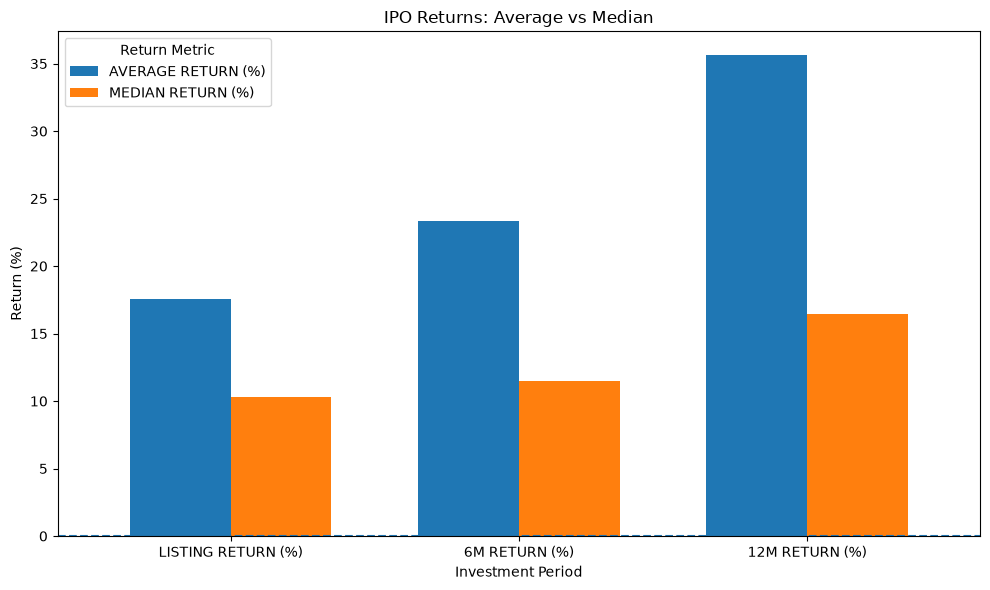

In [89]:
import matplotlib.pyplot as plt

plot_df = performance_summary_df.set_index("PERIOD")[
    ["AVERAGE RETURN (%)", "MEDIAN RETURN (%)"]
]

plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("IPO Returns: Average vs Median")
plt.xlabel("Investment Period")
plt.ylabel("Return (%)")
plt.xticks(rotation=0)
plt.axhline(y=0, linestyle="--")
plt.legend(title="Return Metric")
plt.tight_layout()
plt.show()

## Step 4: Calculate the percentage of profitable IPOs

In [91]:
# Keep IPOs with all three return measurements
complete_ipo_df = master_df.dropna(
    subset=[
        "LISTING RETURN (%)",
        "6M RETURN (%)",
        "12M RETURN (%)"
    ]
).copy()

print("Complete IPO cohort:", len(complete_ipo_df))

paired_summary = complete_ipo_df[
    return_columns
].agg(["mean", "median"]).T

paired_summary.columns = ["AVERAGE RETURN (%)", "MEDIAN RETURN (%)"]

paired_summary = paired_summary.round(2)

paired_summary

Complete IPO cohort: 185


,AVERAGE RETURN (%),MEDIAN RETURN (%)
LISTING RETURN (%),17.53,10.32
6M RETURN (%),23.41,11.68
12M RETURN (%),35.65,15.93


In [92]:
# Convert price columns to numeric
price_columns = [
    "LISTING CLOSE",
    "6M CLOSE",
    "12M CLOSE"
]

for col in price_columns:
    master_df[col] = pd.to_numeric(
        master_df[col],
        errors="coerce"
    )

# Returns for an investor buying at listing-day close
master_df["LISTING TO 6M RETURN (%)"] = (
    (master_df["6M CLOSE"] - master_df["LISTING CLOSE"])
    / master_df["LISTING CLOSE"] * 100
)

master_df["LISTING TO 12M RETURN (%)"] = (
    (master_df["12M CLOSE"] - master_df["LISTING CLOSE"])
    / master_df["LISTING CLOSE"] * 100
)

# Summary
post_listing_summary = master_df[
    [
        "LISTING TO 6M RETURN (%)",
        "LISTING TO 12M RETURN (%)"
    ]
].agg(["count", "mean", "median", "min", "max"]).T

post_listing_summary.round(2)

,count,mean,median,min,max
LISTING TO 6M RETURN (%),185.0,5.49,-3.43,-59.12,187.97
LISTING TO 12M RETURN (%),185.0,15.65,-1.01,-63.82,261.06


In [93]:
post_listing_columns = [
    "LISTING TO 6M RETURN (%)",
    "LISTING TO 12M RETURN (%)"
]

for col in post_listing_columns:
    valid = master_df[col].dropna()

    print(f"\n{col}")
    print("Valid IPOs:", len(valid))
    print("Positive IPOs:", (valid > 0).sum())
    print("Negative IPOs:", (valid < 0).sum())
    print("Positive IPO percentage:",
          round((valid > 0).mean() * 100, 2), "%")


LISTING TO 6M RETURN (%)
Valid IPOs: 185
Positive IPOs: 84
Negative IPOs: 101
Positive IPO percentage: 45.41 %

LISTING TO 12M RETURN (%)
Valid IPOs: 185
Positive IPOs: 90
Negative IPOs: 95
Positive IPO percentage: 48.65 %


In [94]:
master_df.to_csv(master_path, index=False)
print("Updated master dataset saved.")

Updated master dataset saved.


### 3. Next: Understand the distribution of IPO returns

In [95]:
post_listing_columns = [
    "LISTING TO 6M RETURN (%)",
    "LISTING TO 12M RETURN (%)"
]

distribution_summary = master_df[post_listing_columns].describe(
    percentiles=[0.25, 0.50, 0.75]
).T

distribution_summary.round(2)

,count,mean,std,min,25%,50%,75%,max
LISTING TO 6M RETURN (%),185.0,5.49,42.66,-59.12,-20.73,-3.43,21.21,187.97
LISTING TO 12M RETURN (%),185.0,15.65,61.69,-63.82,-27.30,-1.01,32.66,261.06


<Figure size 1000x600 with 0 Axes>

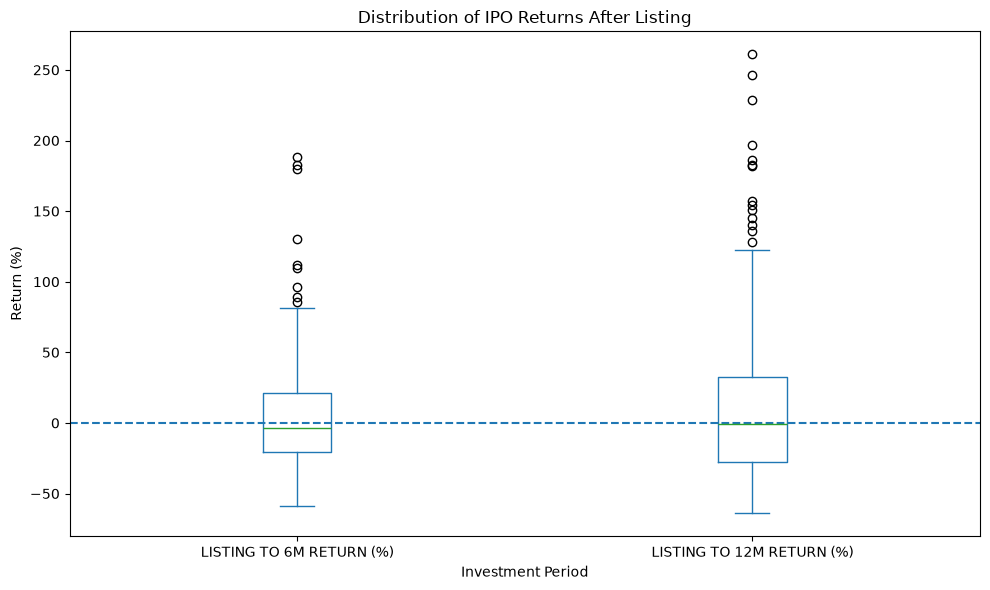

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

master_df[post_listing_columns].plot(
    kind="box",
    figsize=(10, 6)
)

plt.title("Distribution of IPO Returns After Listing")
plt.ylabel("Return (%)")
plt.xlabel("Investment Period")
plt.axhline(y=0, linestyle="--")
plt.tight_layout()
plt.show()

### Step 1: Prepare the subscription data

In [97]:
subscription_columns = [
    "TOTAL SUBSCRIPTION",
    "QIB SUBSCRIPTION",
    "NII SUBSCRIPTION",
    "RETAIL SUBSCRIPTION"
]

for col in subscription_columns:
    master_df[col] = pd.to_numeric(
        master_df[col],
        errors="coerce"
    )

print("Subscription data availability:")
print(master_df[subscription_columns].notna().sum())

print("\nSubscription summary:")
print(master_df[subscription_columns].describe().round(2))

Subscription data availability:
TOTAL SUBSCRIPTION     190
QIB SUBSCRIPTION       190
NII SUBSCRIPTION       190
RETAIL SUBSCRIPTION    190
dtype: int64

Subscription summary:
       TOTAL SUBSCRIPTION  QIB SUBSCRIPTION  NII SUBSCRIPTION  \
count              190.00            190.00            190.00   
mean                43.68             77.80             52.14   
std                 46.39             76.53             76.60   
min                  0.53              1.01              0.20   
25%                  4.71              8.62              3.85   
50%                 27.16             51.31             28.30   
75%                 69.36            134.06             63.20   
max                229.68            331.60            503.83   

       RETAIL SUBSCRIPTION  
count               190.00  
mean                 18.91  
std                  33.53  
min                   0.11  
25%                   2.13  
50%                   7.13  
75%                  21.17  
max   

In [104]:
subscription_return_columns = [
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)",
    "LISTING TO 6M RETURN (%)",
    "LISTING TO 12M RETURN (%)"
]

correlation_results = []

for subscription_col in subscription_columns:

    for return_col in subscription_return_columns:

        temp = master_df[
            [subscription_col, return_col]
        ].dropna()

        if len(temp) >= 2:
            correlation_results.append({
                "SUBSCRIPTION TYPE": subscription_col,
                "RETURN PERIOD": return_col,
                "SAMPLE SIZE": len(temp),
                "PEARSON CORRELATION": temp[subscription_col].corr(
                    temp[return_col],
                    method="pearson"
                ),
                "SPEARMAN CORRELATION": temp[subscription_col].corr(
                    temp[return_col],
                    method="spearman"
                )
            })

correlation_df = pd.DataFrame(correlation_results)

correlation_df.round(3)

,SUBSCRIPTION TYPE,RETURN PERIOD,SAMPLE SIZE,PEARSON CORRELATION,SPEARMAN CORRELATION
0,TOTAL SUBSCRIPTION,LISTING RETURN (%),182,0.593,0.686
1,TOTAL SUBSCRIPTION,6M RETURN (%),186,0.305,0.355
2,TOTAL SUBSCRIPTION,12M RETURN (%),186,0.238,0.272
3,TOTAL SUBSCRIPTION,LISTING TO 6M RETURN (%),182,-0.023,0.028
4,TOTAL SUBSCRIPTION,LISTING TO 12M RETURN (%),182,-0.008,-0.008
5,QIB SUBSCRIPTION,LISTING RETURN (%),182,0.599,0.673
6,QIB SUBSCRIPTION,6M RETURN (%),186,0.310,0.360
7,QIB SUBSCRIPTION,12M RETURN (%),186,0.283,0.301
8,QIB SUBSCRIPTION,LISTING TO 6M RETURN (%),182,-0.002,0.036
9,QIB SUBSCRIPTION,LISTING TO 12M RETURN (%),182,0.050,0.023


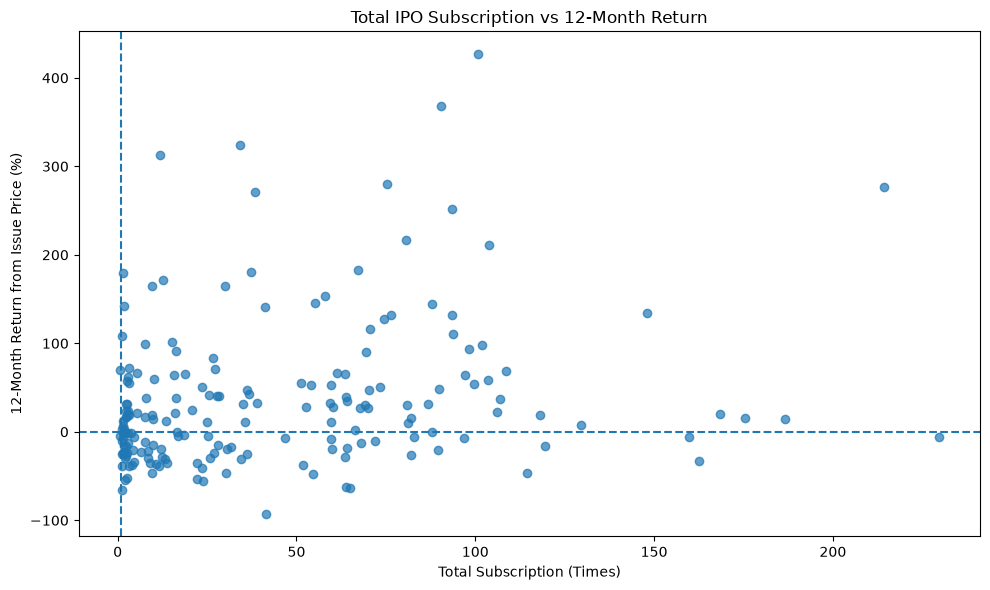

In [105]:
import matplotlib.pyplot as plt

plot_data = master_df[
    ["TOTAL SUBSCRIPTION", "12M RETURN (%)"]
].dropna()

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["TOTAL SUBSCRIPTION"],
    plot_data["12M RETURN (%)"],
    alpha=0.7
)

plt.axhline(y=0, linestyle="--")
plt.axvline(x=1, linestyle="--")

plt.title("Total IPO Subscription vs 12-Month Return")
plt.xlabel("Total Subscription (Times)")
plt.ylabel("12-Month Return from Issue Price (%)")

plt.tight_layout()
plt.show()

In [106]:
conditions = [
    master_df["TOTAL SUBSCRIPTION"] < 1,
    master_df["TOTAL SUBSCRIPTION"].between(1, 3, inclusive="both"),
    (
        (master_df["TOTAL SUBSCRIPTION"] > 3) &
        (master_df["TOTAL SUBSCRIPTION"] <= 10)
    ),
    master_df["TOTAL SUBSCRIPTION"] > 10
]

labels = [
    "Undersubscribed (<1x)",
    "Low (1x-3x)",
    "Moderate (>3x-10x)",
    "High (>10x)"
]

master_df["SUBSCRIPTION CATEGORY"] = np.select(
    conditions,
    labels,
    default="Missing"
)

print(master_df["SUBSCRIPTION CATEGORY"].value_counts())

SUBSCRIPTION CATEGORY
High (>10x)              126
Low (1x-3x)               37
Moderate (>3x-10x)        25
Missing                    4
Undersubscribed (<1x)      2
Name: count, dtype: int64


In [107]:
subscription_performance = (
    master_df[
        master_df["SUBSCRIPTION CATEGORY"] != "Missing"
    ]
    .groupby("SUBSCRIPTION CATEGORY", observed=True)
    .agg(
        IPO_COUNT=("SYMBOL", "count"),
        AVG_LISTING_RETURN=("LISTING RETURN (%)", "mean"),
        AVG_6M_RETURN=("6M RETURN (%)", "mean"),
        AVG_12M_RETURN=("12M RETURN (%)", "mean"),
        MEDIAN_12M_RETURN=("12M RETURN (%)", "median"),
        POSITIVE_12M_IPOS=(
            "12M RETURN (%)",
            lambda x: (x.dropna() > 0).sum()
        )
    )
    .reset_index()
)

subscription_performance.round(2)

,SUBSCRIPTION CATEGORY,IPO_COUNT,AVG_LISTING_RETURN,AVG_6M_RETURN,AVG_12M_RETURN,MEDIAN_12M_RETURN,POSITIVE_12M_IPOS
0,High (>10x),126,27.50,36.13,49.93,28.33,82
1,Low (1x-3x),37,-4.38,-2.67,8.10,-0.81,16
2,Moderate (>3x-10x),25,3.33,4.98,11.16,-3.82,11
3,Undersubscribed (<1x),2,7.49,5.01,32.45,32.45,1
